<a href="https://colab.research.google.com/github/Advanced-Forecasting-Project/NYC-Car-Crashes-Forecasting/blob/Armin-broski/Forecasting_Group.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NYC Motor Vehicle Collisions: Data Cleaning

I will use this notebook to check the crash records and prepare a daily crash-count series for forecasting. I will remove rows only if the crash date is missing or invalid. Will check collision IDs for duplicates and report missing values instead.

## 1. Load and inspect the data

The file is uploaded to this Colab session.

In [1]:
import pandas as pd
url = "https://github.com/Advanced-Forecasting-Project/NYC-Car-Crashes-Forecasting/releases/download/data-v1/Motor_Vehicle_Collisions_-_Crashes.zip"
crashes = pd.read_csv(url, compression="zip", low_memory=False)
print("Rows and columns:", crashes.shape)
print("Columns:", crashes.columns.tolist())
crashes.head()

Rows and columns: (2018963, 29)
Columns: ['CRASH DATE', 'CRASH TIME', 'BOROUGH', 'ZIP CODE', 'LATITUDE', 'LONGITUDE', 'LOCATION', 'ON STREET NAME', 'CROSS STREET NAME', 'OFF STREET NAME', 'NUMBER OF PERSONS INJURED', 'NUMBER OF PERSONS KILLED', 'NUMBER OF PEDESTRIANS INJURED', 'NUMBER OF PEDESTRIANS KILLED', 'NUMBER OF CYCLIST INJURED', 'NUMBER OF CYCLIST KILLED', 'NUMBER OF MOTORIST INJURED', 'NUMBER OF MOTORIST KILLED', 'CONTRIBUTING FACTOR VEHICLE 1', 'CONTRIBUTING FACTOR VEHICLE 2', 'CONTRIBUTING FACTOR VEHICLE 3', 'CONTRIBUTING FACTOR VEHICLE 4', 'CONTRIBUTING FACTOR VEHICLE 5', 'COLLISION_ID', 'VEHICLE TYPE CODE 1', 'VEHICLE TYPE CODE 2', 'VEHICLE TYPE CODE 3', 'VEHICLE TYPE CODE 4', 'VEHICLE TYPE CODE 5']


,CRASH DATE,CRASH TIME,BOROUGH,ZIP CODE,LATITUDE,LONGITUDE,LOCATION,ON STREET NAME,CROSS STREET NAME,OFF STREET NAME,...,CONTRIBUTING FACTOR VEHICLE 2,CONTRIBUTING FACTOR VEHICLE 3,CONTRIBUTING FACTOR VEHICLE 4,CONTRIBUTING FACTOR VEHICLE 5,COLLISION_ID,VEHICLE TYPE CODE 1,VEHICLE TYPE CODE 2,VEHICLE TYPE CODE 3,VEHICLE TYPE CODE 4,VEHICLE TYPE CODE 5
0,09/11/2021,2:39,NaN,NaN,NaN,NaN,NaN,WHITESTONE EXPRESSWAY,20 AVENUE,NaN,...,Unspecified,NaN,NaN,NaN,4455765,Sedan,Sedan,NaN,NaN,NaN
1,03/26/2022,11:45,NaN,NaN,NaN,NaN,NaN,QUEENSBORO BRIDGE UPPER,NaN,NaN,...,NaN,NaN,NaN,NaN,4513547,Sedan,NaN,NaN,NaN,NaN
2,06/29/2022,6:55,NaN,NaN,NaN,NaN,NaN,THROGS NECK BRIDGE,NaN,NaN,...,Unspecified,NaN,NaN,NaN,4541903,Sedan,Pick-up Truck,NaN,NaN,NaN
3,09/11/2021,9:35,BROOKLYN,11208,40.667202,-73.866500,"(40.667202, -73.8665)",NaN,NaN,1211 LORING AVENUE,...,NaN,NaN,NaN,NaN,4456314,Sedan,NaN,NaN,NaN,NaN
4,12/14/2021,8:13,BROOKLYN,11233,40.683304,-73.917274,"(40.683304, -73.917274)",SARATOGA AVENUE,DECATUR STREET,NaN,...,NaN,NaN,NaN,NaN,4486609,NaN,NaN,NaN,NaN,NaN


In [2]:
crash_dates = pd.to_datetime(crashes['CRASH DATE'], format='%m/%d/%Y', errors='coerce')

print('Rows with an invalid date:', crash_dates.isna().sum())
print('First date:', crash_dates.min())
print('Last date:', crash_dates.max())
print('Rows with a missing collision ID:', crashes['COLLISION_ID'].isna().sum())
print('Repeated collision IDs:', crashes['COLLISION_ID'].duplicated().sum())
print('Exact repeated rows:', crashes.duplicated().sum())

Rows with an invalid date: 0
First date: 2012-07-01 00:00:00
Last date: 2023-08-18 00:00:00
Rows with a missing collision ID: 0
Repeated collision IDs: 0
Exact repeated rows: 0


In [3]:
missing_summary = pd.DataFrame({
    "missing_count": crashes.isna().sum(),
    "missing_percent": (crashes.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)

missing_summary

,missing_count,missing_percent
VEHICLE TYPE CODE 5,2010550,99.58
CONTRIBUTING FACTOR VEHICLE 5,2010288,99.57
VEHICLE TYPE CODE 4,1987893,98.46
CONTRIBUTING FACTOR VEHICLE 4,1986822,98.41
VEHICLE TYPE CODE 3,1880762,93.15
CONTRIBUTING FACTOR VEHICLE 3,1875772,92.91
OFF STREET NAME,1686327,83.52
CROSS STREET NAME,755889,37.44
ZIP CODE,628305,31.12
BOROUGH,628067,31.11


In [4]:
# Keep rows with a valid crash date.
cleaned = crashes.loc[crash_dates.notna()].copy()
cleaned["CRASH DATE"] = crash_dates[crash_dates.notna()]

# Count crashes by day and include dates with no recorded crashes.
daily_crashes = cleaned.groupby("CRASH DATE").size().asfreq("D", fill_value=0)
daily_crashes.name = "crash_count"

# Weekly totals make a second series to compare later.
weekly_crashes = daily_crashes.resample("W").sum()

print("Rows kept:", len(cleaned))
print("Rows removed for invalid dates:", len(crashes) - len(cleaned))
print("Daily series:", daily_crashes.index.min(), "to", daily_crashes.index.max())
print("Days with no recorded crashes:", (daily_crashes == 0).sum())
print("Number of weeks:", len(weekly_crashes))
print("The first and last weeks may be partial weeks.")

# Save the daily and weekly counts for the forecasting work.
daily_crashes.to_csv("nyc_daily_crash_counts.csv")
weekly_crashes.to_csv("nyc_weekly_crash_counts.csv")

Rows kept: 2018963
Rows removed for invalid dates: 0
Daily series: 2012-07-01 00:00:00 to 2023-08-18 00:00:00
Days with no recorded crashes: 0
Number of weeks: 582
The first and last weeks may be partial weeks.


In [5]:
# Check the first and last monthly totals because these months are incomplete.
monthly_crashes = daily_crashes.resample("MS").sum()
print("First month and crash count:")
print(monthly_crashes.head(1))
print("Last month and crash count:")
print(monthly_crashes.tail(1))

First month and crash count:
CRASH DATE
2012-07-01    16992
Freq: MS, Name: crash_count, dtype: int64
Last month and crash count:
CRASH DATE
2023-08-01    4274
Freq: MS, Name: crash_count, dtype: int64


In [6]:
# Show the data type saved for each column.
data_types = crashes.dtypes.astype(str).rename("data_type").reset_index()
data_types.columns = ["column", "data_type"]
data_types

,column,data_type
0,CRASH DATE,object
1,CRASH TIME,object
2,BOROUGH,object
3,ZIP CODE,object
4,LATITUDE,float64
5,LONGITUDE,float64
6,LOCATION,object
7,ON STREET NAME,object
8,CROSS STREET NAME,object
9,OFF STREET NAME,object


### What the columns describe

Each row is one police-reported motor vehicle collision. **CRASH DATE** and **CRASH TIME** record when it happened. **BOROUGH**, **ZIP CODE**, coordinates and street names describe where it happened. The injury and fatality columns contain counts. The contributing factor and vehicle type columns describe reported crash details. **COLLISION_ID** identifies a crash record.
For a city wide daily crash forecast, the crash date is used to group records and the number of records becomes the target.

Source: [NYC Open Data, Motor Vehicle Collisions – Crashes](https://www.kaggle.com/datasets/ishmaelkiptoo/motor-vehicle-collisions$0)

In [7]:
import os

# The raw data is read straight from the URL, so only the saved files are checked.
for name in ["nyc_daily_crash_counts.csv", "nyc_weekly_crash_counts.csv"]:
    size_mb = os.path.getsize(name) / (1024 ** 2)
    print(name, round(size_mb, 2), "MB")

daily_saved = pd.read_csv("nyc_daily_crash_counts.csv")
weekly_saved = pd.read_csv("nyc_weekly_crash_counts.csv")
print("Daily CSV rows and total:", len(daily_saved), daily_saved["crash_count"].sum())
print("Weekly CSV rows and total:", len(weekly_saved), weekly_saved["crash_count"].sum())
print("Raw crash rows:", len(crashes))

nyc_daily_crash_counts.csv 0.06 MB
nyc_weekly_crash_counts.csv 0.01 MB
Daily CSV rows and total: 4066 2018963
Weekly CSV rows and total: 582 2018963
Raw crash rows: 2018963


## 2. Problem definition, validation set-up and baselines

This chapter starts from the data loaded and checked in Chapter 1 and proposes, for the team to vote on:

1. the **forecasting target**,
2. the **forecast horizons**,
3. the **train / validation / test split** and the **rolling-origin cross-validation** scheme,
4. the **evaluation metrics**,
5. **baseline scores** (naive and seasonal naive) under that set-up.

The settings and helper functions in Section 2.0 are meant to be copied unchanged into each individual notebook, so that all models are scored in exactly the same way.

> **Status: draft.** The split depends on Person 2's (Mia's) outlier and COVID findings. All split dates are set in one cell (Section 2.0), so moving them means changing a single cell. Open questions for Mia are listed in Section 2.9.

### 2.0 Set-up: imports, agreed settings and helper functions

The first cell installs `statsforecast` if it is missing (as in class) and imports the libraries. The second cell holds **every setting the team agrees on**: split dates, horizon and the spacing of forecast origins. The third defines the functions used to build the daily series, run the rolling-origin backtest and compute the metrics.

**The settings and helper-function cells should be copied unchanged into each individual notebook.** If the team changes the split after Mia's findings, only the settings cell changes.

In [8]:
import subprocess, sys
try:
    import statsforecast
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "statsforecast"], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.graphics.tsaplots import plot_acf
from statsforecast import StatsForecast
from statsforecast.models import Naive, SeasonalNaive

pd.set_option("display.precision", 2)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
COVID_START = pd.Timestamp("2020-03-01")

In [9]:
# ---- Group-agreed settings (proposal, to be confirmed by vote) ----
FREQ = "D"
SEASON_LENGTH = 7      # weekly cycle in daily data
HORIZON = 28           # each forecast covers the next 28 days (4 full weeks)
STEP_SIZE = 29         # a new forecast origin every 29 days (29 = 4*7 + 1, so the origin weekday rotates)
MASE_WINDOW = 365      # MASE scale uses the last year before each origin (see Section 2.6)

TRAIN_END = pd.Timestamp("2021-12-31")
VALID_START, VALID_END = pd.Timestamp("2022-01-01"), pd.Timestamp("2022-12-31")
TEST_START, TEST_END = pd.Timestamp("2023-01-01"), pd.Timestamp("2023-08-18")
PERIODS = {"validation": (VALID_START, VALID_END),   # model choice and tuning
           "test": (TEST_START, TEST_END)}           # used once, at the end

# Groups of forecast steps reported by evaluate(): the 7-day and 28-day horizons
HORIZON_BUCKETS = {"h 1-7": (1, 7), "h 8-28": (8, 28), "h 1-28": (1, 28)}

# Candidate targets: None = count crash records, otherwise sum this column
TARGETS = {"crash_count": None,
           "persons_injured": "NUMBER OF PERSONS INJURED",
           "persons_killed": "NUMBER OF PERSONS KILLED"}

In [10]:
# ---- Helper functions ----

def to_daily(crashes, target="crash_count"):
    # Daily series in statsforecast format (unique_id, ds, y), same steps as Chapter 1.
    dates = pd.to_datetime(crashes["CRASH DATE"], format="%m/%d/%Y", errors="coerce")
    valid = dates.notna()
    col = TARGETS[target]
    if col is None:
        daily = dates[valid].value_counts().sort_index()
    else:
        daily = crashes.loc[valid, col].fillna(0).groupby(dates[valid]).sum()
    daily = daily.asfreq(FREQ, fill_value=0).astype(float)
    return pd.DataFrame({"unique_id": target, "ds": daily.index, "y": daily.to_numpy()})


def get_cutoffs(period, h=HORIZON, step_size=STEP_SIZE):
    # Forecast origins (last training day), placed backwards from the period end
    # exactly as StatsForecast.cross_validation places them.
    start, end = PERIODS[period]
    n_windows = ((end - start).days + 1 - h) // step_size + 1
    last = end - pd.Timedelta(h, unit="D")
    return sorted(last - pd.Timedelta(k * step_size, unit="D") for k in range(n_windows))


def cv_config(df, period, h=HORIZON, step_size=STEP_SIZE):
    # Data (cut at the period end) and arguments for StatsForecast.cross_validation.
    end = PERIODS[period][1]
    n_windows = len(get_cutoffs(period, h, step_size))
    return df[df["ds"] <= end].copy(), {"h": h, "step_size": step_size, "n_windows": n_windows}


def backtest(forecast_fn, df, period, model_name="model", h=HORIZON, step_size=STEP_SIZE,
             train_start=None):
    # Rolling-origin backtest for any model, with the same output format as statsforecast.
    # forecast_fn(train_df, h) must return h forecasts for the days after the cutoff.
    rows = []
    for cutoff in get_cutoffs(period, h, step_size):
        train = df[df["ds"] <= cutoff]
        if train_start is not None:
            train = train[train["ds"] >= pd.Timestamp(train_start)]
        future = df[(df["ds"] > cutoff) & (df["ds"] <= cutoff + pd.Timedelta(h, unit="D"))]
        y_hat = np.asarray(forecast_fn(train.copy(), h), dtype=float)
        rows.append(pd.DataFrame({"unique_id": future["unique_id"].to_numpy(),
                                  "ds": future["ds"].to_numpy(), "cutoff": cutoff,
                                  "y": future["y"].to_numpy(), model_name: y_hat}))
    return pd.concat(rows, ignore_index=True)


# Metrics
def mae(y, y_hat):  return np.mean(np.abs(np.asarray(y) - np.asarray(y_hat)))
def rmse(y, y_hat): return np.sqrt(np.mean((np.asarray(y) - np.asarray(y_hat)) ** 2))
def bias(y, y_hat): return np.mean(np.asarray(y) - np.asarray(y_hat))   # > 0: under-forecast

def mape(y, y_hat):
    y, y_hat = np.asarray(y, dtype=float), np.asarray(y_hat, dtype=float)
    mask = y != 0                                    # skip zero days
    return np.mean(np.abs((y[mask] - y_hat[mask]) / y[mask])) * 100

def mase_scale(history, season_length=SEASON_LENGTH, window=MASE_WINDOW):
    # In-sample MAE of the seasonal naive forecast over the last `window` days.
    h = np.asarray(history, dtype=float)[-window:]
    return np.mean(np.abs(h[season_length:] - h[:-season_length]))


def add_horizon(cv_df):
    out = cv_df.copy()
    out["h"] = (out["ds"] - out["cutoff"]).dt.days   # 1 = the day after the cutoff
    return out


def evaluate(cv_df, history, models=None, per_window=False):
    # Scores per model and horizon group, averaged over forecast origins.
    # history = the full daily series (used for the MASE scale, up to each cutoff only).
    models = models or [c for c in cv_df.columns if c not in ["unique_id", "ds", "cutoff", "y"]]
    df = add_horizon(cv_df)
    rows = []
    for cutoff, win in df.groupby("cutoff"):
        scale = mase_scale(history.loc[history["ds"] <= cutoff, "y"])
        for label, (lo, hi) in HORIZON_BUCKETS.items():
            part = win[(win["h"] >= lo) & (win["h"] <= hi)]
            for m in models:
                rows.append({"model": m, "horizon": label, "cutoff": cutoff,
                             "MAE": mae(part["y"], part[m]), "RMSE": rmse(part["y"], part[m]),
                             "MAPE": mape(part["y"], part[m]),
                             "MASE": mae(part["y"], part[m]) / scale,
                             "Bias": bias(part["y"], part[m])})
    scores = pd.DataFrame(rows)
    if per_window:
        return scores
    return scores.groupby(["model", "horizon"], sort=False).agg(
        MAE=("MAE", "mean"), RMSE=("RMSE", "mean"), MAPE=("MAPE", "mean"),
        MASE=("MASE", "mean"), Bias=("Bias", "mean"),
        MAE_sd=("MAE", "std"), n_windows=("MAE", "size"))


def evaluate_by_horizon(cv_df, models=None):
    # MAE for each forecast step h (rows) and model (columns), averaged over origins.
    models = models or [c for c in cv_df.columns if c not in ["unique_id", "ds", "cutoff", "y"]]
    df = add_horizon(cv_df)
    return pd.DataFrame({m: df.groupby("h")[["y", m]].apply(lambda g, m=m: mae(g["y"], g[m]))
                         for m in models})

### 2.1 From crash records to daily series

Chapter 1 found no invalid dates, no duplicate collision IDs and no missing calendar days. `to_daily()` repeats the Chapter 1 aggregation (parse `CRASH DATE`, count records per day, keep every calendar day) and returns the result in the format statsforecast expects (`unique_id`, `ds`, `y`). It also builds the injury and fatality series compared below. The check confirms it gives exactly the same counts as `daily_crashes` from Chapter 1.

In [11]:
# `crashes` was loaded in Chapter 1.
# Three candidate daily series in Nixtla format (unique_id, ds, y)
candidates = {t: to_daily(crashes, target=t) for t in TARGETS}
daily = candidates["crash_count"]
print("Daily series:", daily["ds"].min().date(), "to", daily["ds"].max().date(), "|", len(daily), "days")
print("Same counts as daily_crashes in Chapter 1:",
      np.array_equal(daily["y"].to_numpy(), daily_crashes.to_numpy()))

Daily series: 2012-07-01 to 2023-08-18 | 4066 days
Same counts as daily_crashes in Chapter 1: True


### 2.2 Target

#### Options

The data supports three natural city-wide daily targets:

| Option | Practical use |
|---|---|
| **Total crashes per day** (number of records) | Police patrol and traffic-unit staffing, tow and response capacity, report processing workload |
| **Persons injured per day** | Ambulance (EMS) and emergency-department planning |
| **Persons killed per day** | Road-safety policy (e.g. Vision Zero monitoring) |

The table and plot below compare their statistical properties.

In [12]:
rows = {}
for name, d in candidates.items():
    s = d.set_index("ds")["y"]
    rows[name] = {
        "mean per day": s.mean(),
        "mean 2019": s["2019"].mean(),
        "mean 2022": s["2022"].mean(),
        "change 2019 to 2022 (%)": 100 * (s["2022"].mean() / s["2019"].mean() - 1),
        "coef. of variation 2022+": s["2022":].std() / s["2022":].mean(),
        "days with 0 (%)": 100 * (s == 0).mean(),
    }
target_summary = pd.DataFrame(rows).T
target_summary

,mean per day,mean 2019,mean 2022,change 2019 to 2022 (%),coef. of variation 2022+,days with 0 (%)
crash_count,496.55,579.41,284.56,-50.89,0.13,0.00
persons_injured,150.23,168.19,142.24,-15.43,0.19,0.00
persons_killed,0.72,0.67,0.79,17.62,1.26,51.21


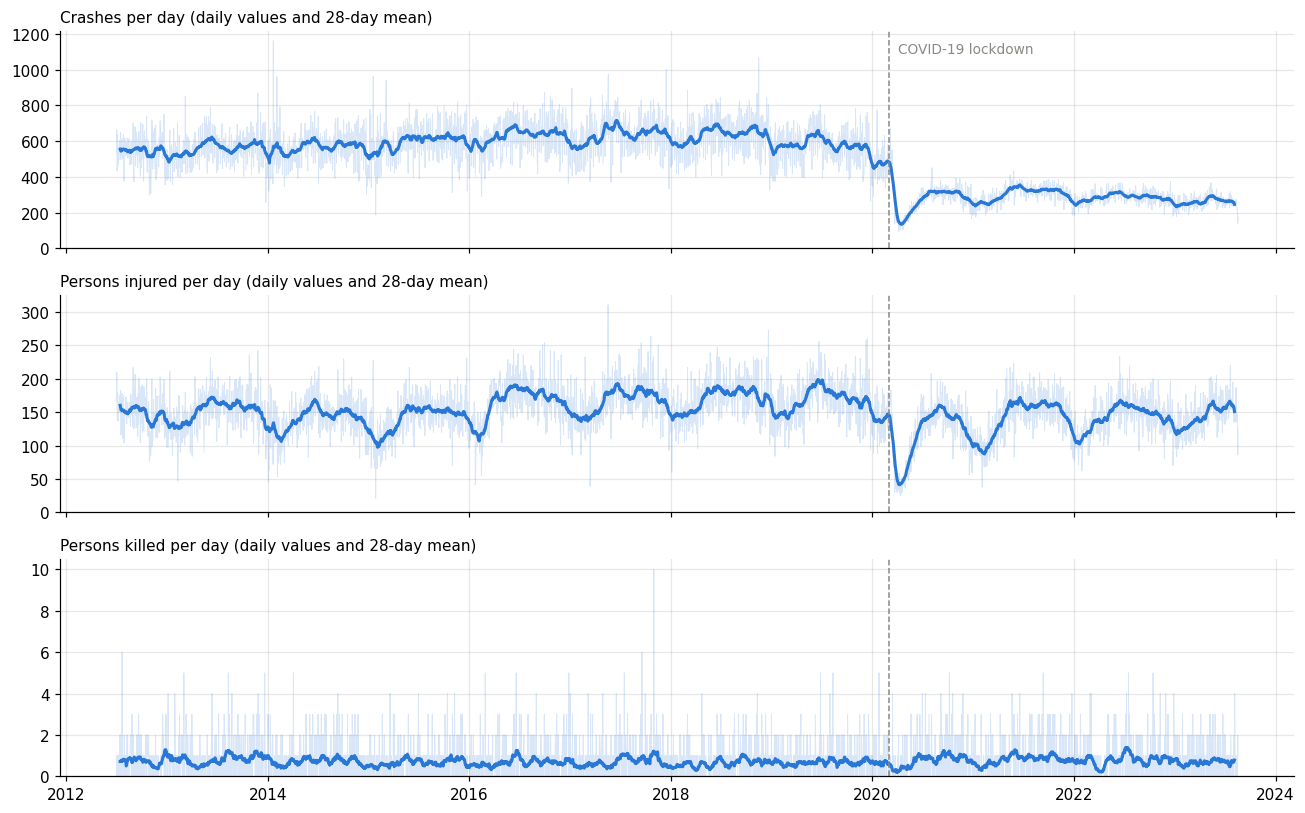

In [13]:
labels = {"crash_count": "Crashes per day", "persons_injured": "Persons injured per day",
          "persons_killed": "Persons killed per day"}
fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True)
for ax, (name, d) in zip(axes, candidates.items()):
    s = d.set_index("ds")["y"]
    ax.plot(s.index, s, color=BLUE, alpha=0.18, lw=0.6)
    ax.plot(s.index, s.rolling(28, center=True).mean(), color=BLUE, lw=2)
    ax.axvline(COVID_START, color=GREY, ls="--", lw=1)
    ax.set_title(f"{labels[name]} (daily values and 28-day mean)", loc="left", fontsize=10)
    ax.set_ylim(bottom=0)
axes[0].annotate("COVID-19 lockdown", xy=(COVID_START, axes[0].get_ylim()[1] * 0.9),
                 xytext=(6, 0), textcoords="offset points", color=GREY, fontsize=9)
plt.tight_layout()
plt.show()

#### Recommendation: total crashes per day

**Proposed main target: the daily number of police-reported crashes in New York City.**

* **Strongest signal.** There are around 500 crashes per day on average (about 285 per day since 2022), with no zero days. That supports daily forecasting and every metric we want to use, including percentage errors.
* **Fatalities are not forecastable at daily resolution.** About half of all days have no deaths, and the mean is below one per day. The series is mostly noise at this frequency, MAPE is undefined on zero days, and a useful fatality forecast would need monthly or yearly aggregation.
* **Crash counts match a concrete planning decision.** Every reported crash needs police attention and a report (NYPD form MV-104AN), so the count maps directly onto patrol and traffic-unit staffing.
* **It is the series Polly already prepared** (`nyc_daily_crash_counts.csv`), so all notebooks start from the same validated numbers.

**Caveat to discuss with Mia:** crashes fell by about half between 2019 and 2022, while injuries fell by only about 15%. This could be real (less traffic, fewer minor crashes) or a change in what gets recorded. The model does not need to explain it, but the forecast should only be interpreted against the post-2020 level.

**Secondary target (optional):** persons injured per day. It is more relevant for hospital planning and has a smaller structural break. `to_daily(crashes, target="persons_injured")` returns it in the same format, so anyone can rerun their model on it with no other changes.

### 2.3 Horizons

Weekly seasonality decides the horizon design. Before 2020, Fridays were the busiest day and Sundays the quietest, at almost 20% below average. Since the pandemic the weekly pattern has flattened but is still there. The plot indexes each weekday to that period's weekly average (= 100) so that the two periods can be compared despite the level shift.

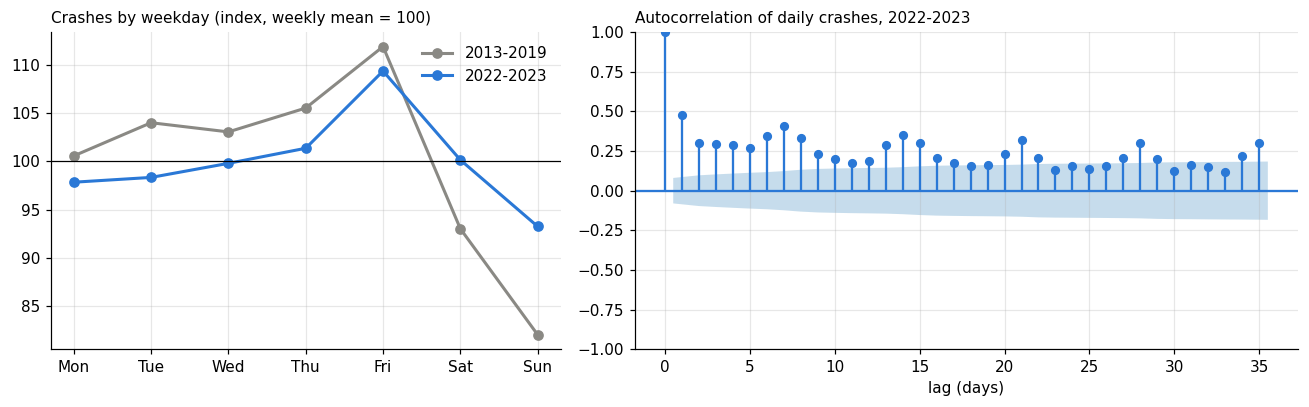

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
2013-2019,100.6,104.0,103.0,105.5,111.9,93.0,82.0
2022-2023,97.8,98.3,99.8,101.3,109.3,100.1,93.2


In [14]:
s = daily.set_index("ds")["y"]
dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
profiles = {}
for label, part in {"2013-2019": s["2013":"2019"], "2022-2023": s["2022":]}.items():
    prof = part.groupby(part.index.dayofweek).mean()
    profiles[label] = 100 * prof / prof.mean()
profiles = pd.DataFrame(profiles, index=range(7)).set_axis(dow_names)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.3]})
for (label, col), color in zip(profiles.items(), [GREY, BLUE]):
    ax1.plot(dow_names, col, marker="o", ms=6, lw=2, color=color, label=label)
ax1.axhline(100, color="black", lw=0.8)
ax1.set_title("Crashes by weekday (index, weekly mean = 100)", loc="left", fontsize=10)
ax1.legend(frameon=False)

plot_acf(s["2022":], lags=35, ax=ax2, title="", color=BLUE, vlines_kwargs={"colors": BLUE})
ax2.set_title("Autocorrelation of daily crashes, 2022-2023", loc="left", fontsize=10)
ax2.set_xlabel("lag (days)")
plt.tight_layout()
plt.show()
profiles.round(1).T

**Proposed horizons: 7 days and 28 days ahead.** Each forecast is made once, for the next 28 days. It is scored on days 1–7 (the short horizon) and on days 1–28 (the long horizon); days 8–28 are also reported on their own to show how accuracy decays.

* **7 days, for operational rostering.** Police shift rosters and overtime are planned about a week ahead. A full week also contains every weekday exactly once, so the weekly pattern cannot flatter or punish a model depending on which day the forecast starts.
* **28 days, for monthly resource planning.** This covers monthly staffing budgets, scheduling of enforcement campaigns and EMS capacity planning. We use 28 rather than 30 days because 28 is exactly four weeks: every forecast contains the same number of each weekday, so errors are comparable across forecast origins.
* **Not longer than 28 days.** The autocorrelation decays slowly beyond the weekly peaks at lags 7, 14, 21 and 28, but longer horizons would push us into yearly seasonality. Our post-COVID history contains only about two clean years, which makes yearly effects hard to learn and to validate.

The weekly pattern makes **seasonal naive with period 7** the natural baseline. Plain **naive** (repeat the last day) is a useful second reference point because the level has shifted (Section 2.7).

### 2.4 Train / validation / test split and the COVID-19 break

The series has a structural break in March 2020. Daily crashes fell from about 550 to about 140 in April 2020, partly recovered by summer 2020, and then settled at roughly half the pre-2020 level. They have drifted slowly down since. Three facts drive the split:

1. **Validation and test must come from the "new normal".** The forecasts are meant for current planning, so models should be judged on post-COVID behaviour. Scoring them on the lockdown months would mostly reward whichever model happens to handle a one-off shock, not routine forecasting.
2. **The recovery period (mid-2020 to 2021) is unstable**, so it should not be used for evaluation. It can still be used for training.
3. **The data end on 2023-08-18**, which leaves about 1.6 years of settled post-COVID data for validation and testing.

In [15]:
print("Monthly mean crashes per day around the break:")
print(s.resample("MS").mean()["2019-10":"2021-06"].round(0).to_frame("crashes/day").T.to_string())

Monthly mean crashes per day around the break:
ds           2019-10-01  2019-11-01  2019-12-01  2020-01-01  2020-02-01  2020-03-01  2020-04-01  2020-05-01  2020-06-01  2020-07-01  2020-08-01  2020-09-01  2020-10-01  2020-11-01  2020-12-01  2021-01-01  2021-02-01  2021-03-01  2021-04-01  2021-05-01  2021-06-01
crashes/day       568.0       565.0       550.0       463.0       473.0       357.0       138.0       199.0       255.0       299.0       317.0       320.0       313.0       301.0       270.0       249.0       249.0       267.0       292.0       332.0       354.0


#### Proposed split (by date, no shuffling)

| Part | Dates | Days | Use |
|---|---|---|---|
| **Training** | 2012-07-01 → 2021-12-31 | 3,471 | Fitting. Each member may start later (e.g. from 2020-07-01) if their model cannot cope with the level shift, but must state it. |
| **Validation** | 2022-01-01 → 2022-12-31 | 365 | Model selection and hyperparameter tuning, using rolling-origin CV |
| **Test** | 2023-01-01 → 2023-08-18 | 230 | Final scoring, run **once**, after all tuning is finished, using the same rolling-origin scheme |

Why a full calendar year for validation? It contains every month once, so no model is tuned only on, say, summer behaviour. The test period is what remains after that.

**Alternatives for the vote:**

* **(A) Proposed:** all history is available for training; validation is 2022 and test is 2023.
* **(B) Post-COVID-only training:** like (A), but every model must start training from 2020-07-01. This is fairer between models, but leaves only about 18 months of training data at the first validation origin, too short for most models to learn anything yearly.
* **(C) Pre-COVID evaluation:** validation in 2018 and test in 2019, ignoring 2020 onwards. It is cleaner statistically, but less relevant to present-day planning, so this proposal does not recommend it.

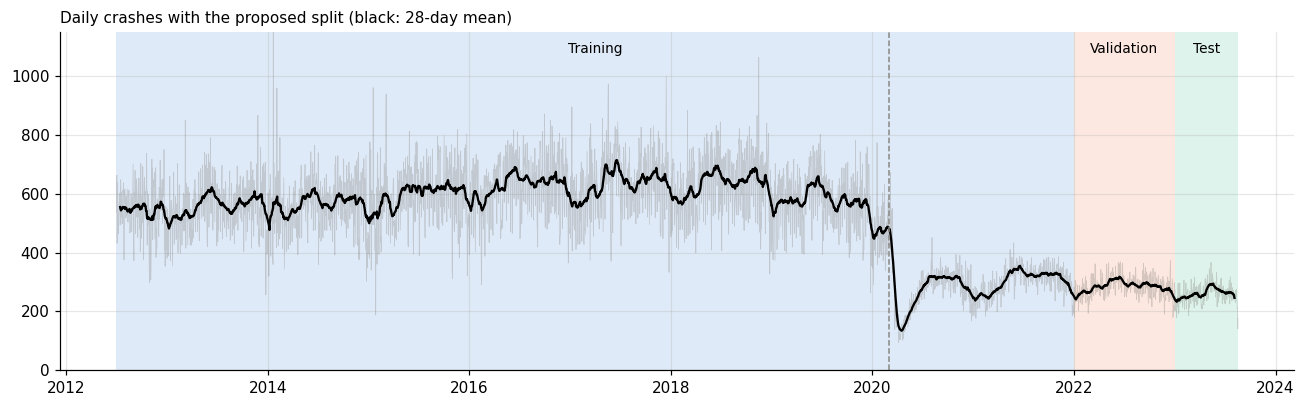

In [16]:
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(s.index, s, color=GREY, alpha=0.35, lw=0.5)
ax.plot(s.index, s.rolling(28, center=True).mean(), color="black", lw=1.5)
spans = [("Training", s.index.min(), TRAIN_END, BLUE),
         ("Validation", VALID_START, VALID_END, ORANGE),
         ("Test", TEST_START, TEST_END, AQUA)]
for label, a, b, color in spans:
    ax.axvspan(a, b, color=color, alpha=0.15, lw=0)
    ax.text(a + (b - a) / 2, 1080, label, ha="center", fontsize=9)
ax.axvline(COVID_START, color=GREY, ls="--", lw=1)
ax.set_ylim(0, 1150)
ax.set_title("Daily crashes with the proposed split (black: 28-day mean)", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

### 2.5 Rolling-origin cross-validation

A single validation split gives one number from one forecast origin, and that number depends heavily on which weeks it happens to cover. Following Tashman (2000) and the class approach, we **refit and forecast from many origins** (expanding window):

* At each **cutoff** (forecast origin), the model is trained on all data up to and including that day and forecasts the next **h = 28** days.
* Cutoffs are **29 days apart**: 12 origins in the validation year and 7 in the test period. Windows do not overlap, so each day is scored at most once.
* **Why 29 and not 28?** With a step of 28, every origin falls on the same weekday. When we tried that first, the naive forecast's score depended mostly on whether that weekday happened to be busy or quiet. A 29-day step moves the origin forward by one weekday each time, so the 7 test origins cover each weekday exactly once.
* Windows are placed backwards from the end of each period, exactly as `StatsForecast.cross_validation` places them. As a result, the first few days of each period are used only as history (validation scoring starts after 2022-01-18, test scoring after 2023-01-28).

The scheme is implemented in two interchangeable ways:

* `cv_config(daily, period)` gives the data and arguments for `StatsForecast.cross_validation`.
* `backtest(forecast_fn, daily, period)` does the same for any other model (Prophet, scikit-learn, neural networks). Section 2.7 checks that the two produce identical results.

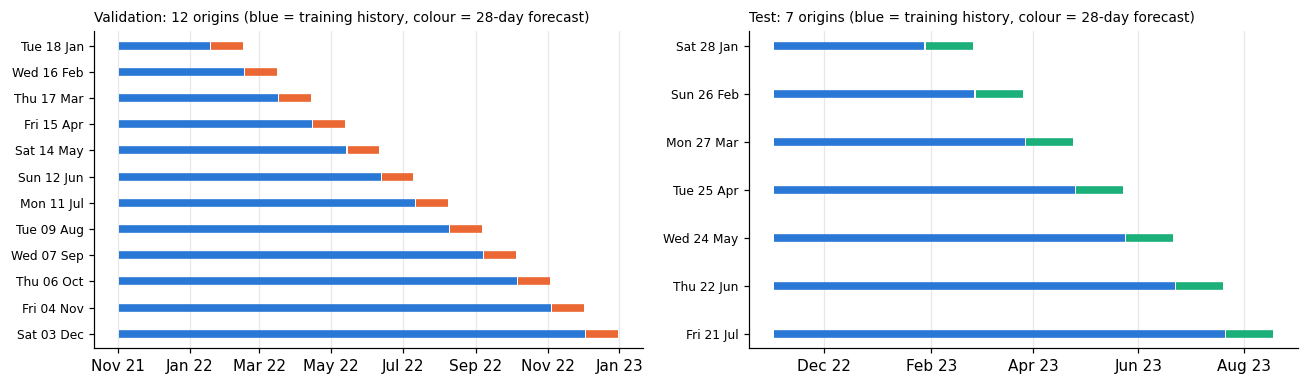

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=False)
for ax, period, color in zip(axes, ["validation", "test"], [ORANGE, AQUA]):
    cutoffs = get_cutoffs(period)
    start = PERIODS[period][0] - pd.Timedelta(60, unit="D")
    for i, c in enumerate(cutoffs):
        ax.plot([start, c], [i, i], color=BLUE, lw=5, solid_capstyle="butt")
        ax.plot([c + pd.Timedelta(1, unit="D"), c + pd.Timedelta(HORIZON, unit="D")], [i, i],
                color=color, lw=5, solid_capstyle="butt")
    ax.invert_yaxis()
    ax.set_yticks(range(len(cutoffs)), [f"{c:%a %d %b}" for c in cutoffs], fontsize=8)
    ax.set_title(f"{period.capitalize()}: {len(cutoffs)} origins "
                 f"(blue = training history, colour = 28-day forecast)", loc="left", fontsize=9)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### 2.6 Evaluation metrics

`evaluate()` reports the following metrics for each model and horizon. Each is averaged over the forecast origins:

| Metric | Why we use it |
|---|---|
| **MAE** (primary) | Measured in crashes per day, so it translates directly into staffing (e.g. "on average we are 30 crashes off"). It is robust to the occasional extreme day (storms, holidays), which we do not want to dominate model choice. **Models are ranked by MAE on h 1–28.** |
| **RMSE** | Penalises large misses more heavily. A big under-forecast means an understaffed shift, so a model that is usually close but occasionally badly wrong should be visible. The gap between RMSE and MAE tells us how heavy-tailed the errors are. |
| **MAPE** | Easy to communicate to non-technical stakeholders ("about 10% off"). It is safe here because the series never comes close to zero (minimum 94). We prefer it to sMAPE, which is harder to explain and still asymmetric (Hyndman and Athanasopoulos, 2021). We remember that MAPE penalises over-forecasts more than under-forecasts. |
| **MASE** | MAE divided by the in-sample MAE of the seasonal naive forecast (Hyndman and Koehler, 2006), so below 1 means better than a one-step seasonal naive forecast. Because of the COVID level shift, the scale uses only the **last 365 days before each cutoff**. Scaling by the full history (which includes busier pre-2020 years) would make every model look about twice as good as it is. |
| **Bias** (mean error, actual − forecast) | Positive values mean the model systematically under-forecasts. This matters for planning and is invisible in the absolute metrics. |
| **MAE_sd** | Standard deviation of MAE across origins. This is a **stability** measure, which the assignment asks us to discuss. |

We do not use MAPE or sMAPE on the fatalities series, where zero days make them undefined.

### 2.7 Baselines: naive and seasonal naive

Both baselines are fitted with `statsforecast`, as in class:

* **Naive:** every day in the next 28 is forecast as the last observed value.
* **Seasonal naive (period 7):** each day is forecast as the same weekday of the last observed week.

In [18]:
baselines = [Naive(), SeasonalNaive(season_length=SEASON_LENGTH)]
cv_results = {}
for period in ["validation", "test"]:
    df_cv, cv_kwargs = cv_config(daily, period)
    sf = StatsForecast(models=baselines, freq=FREQ)
    cv_results[period] = sf.cross_validation(df=df_cv, **cv_kwargs)
    print(period, cv_kwargs)

cv_results["validation"].head()

validation {'h': 28, 'step_size': 29, 'n_windows': 12}
test {'h': 28, 'step_size': 29, 'n_windows': 7}


,unique_id,ds,cutoff,y,Naive,SeasonalNaive
0,crash_count,2022-01-19,2022-01-18,255.0,258.0,250.0
1,crash_count,2022-01-20,2022-01-18,246.0,258.0,268.0
2,crash_count,2022-01-21,2022-01-18,288.0,258.0,289.0
3,crash_count,2022-01-22,2022-01-18,267.0,258.0,236.0
4,crash_count,2022-01-23,2022-01-18,229.0,258.0,266.0


**Sanity check of `backtest()`.** A hand-written seasonal naive model, run through the generic backtest loop, must give exactly the same forecasts as statsforecast. This confirms that teammates using other libraries are scored on identical origins and windows.

In [19]:
def seasonal_naive_fn(train, h):
    last_week = train["y"].to_numpy()[-SEASON_LENGTH:]
    return np.resize(last_week, h)

check = backtest(seasonal_naive_fn, daily, "validation", model_name="snaive_manual")
same_cutoffs = (check["cutoff"].unique() == cv_results["validation"]["cutoff"].unique()).all()
max_diff = np.abs(check["snaive_manual"].to_numpy() - cv_results["validation"]["SeasonalNaive"].to_numpy()).max()
print("Same cutoffs:", same_cutoffs, "| max difference in forecasts:", max_diff)

Same cutoffs: True | max difference in forecasts: 0.0


#### Validation scores

In [20]:
val_scores = evaluate(cv_results["validation"], history=daily)
val_scores

,,MAE,RMSE,MAPE,MASE,Bias,MAE_sd,n_windows
model,horizon,,,,,,,
Naive,h 1-7,32.67,38.97,11.60,1.06,2.33,13.08,12
SeasonalNaive,h 1-7,29.32,36.81,10.84,0.95,-4.11,8.00,12
Naive,h 8-28,29.67,36.24,10.50,0.96,4.80,8.15,12
SeasonalNaive,h 8-28,29.03,36.30,10.46,0.94,-1.64,5.30,12
Naive,h 1-28,30.42,37.27,10.78,0.98,4.18,8.60,12
SeasonalNaive,h 1-28,29.10,36.76,10.55,0.94,-2.26,4.74,12


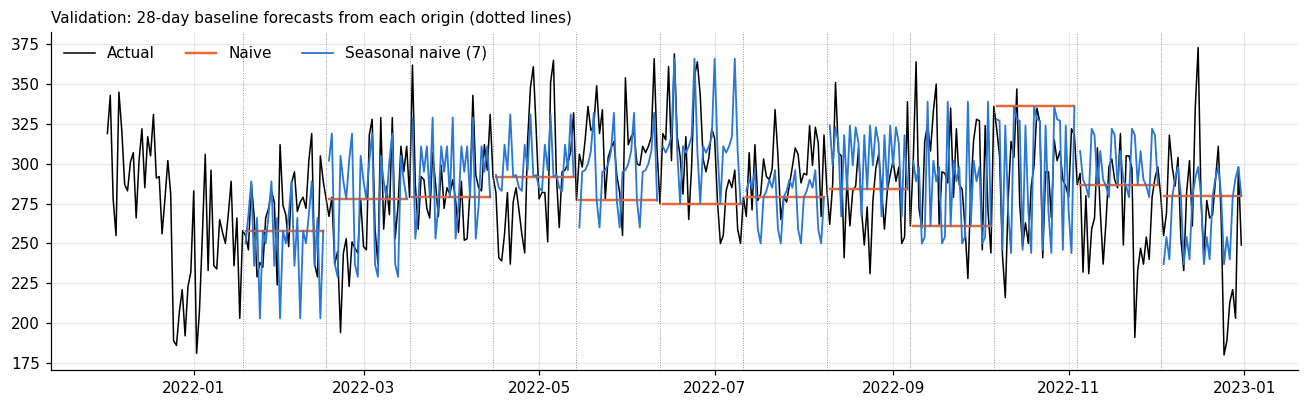

In [21]:
cv_val = cv_results["validation"]
fig, ax = plt.subplots(figsize=(12, 3.8))
hist = s[VALID_START - pd.Timedelta(30, unit="D"):VALID_END]
ax.plot(hist.index, hist, color="black", lw=1, label="Actual")
for i, (cutoff, win) in enumerate(cv_val.groupby("cutoff")):
    ax.plot(win["ds"], win["Naive"], color=ORANGE, lw=1.6, label="Naive" if i == 0 else None)
    ax.plot(win["ds"], win["SeasonalNaive"], color=BLUE, lw=1.2, label="Seasonal naive (7)" if i == 0 else None)
    ax.axvline(cutoff, color=GREY, lw=0.6, ls=":")
ax.set_title("Validation: 28-day baseline forecasts from each origin (dotted lines)", loc="left", fontsize=10)
ax.legend(frameon=False, ncol=3, loc="upper left")
plt.tight_layout()
plt.show()

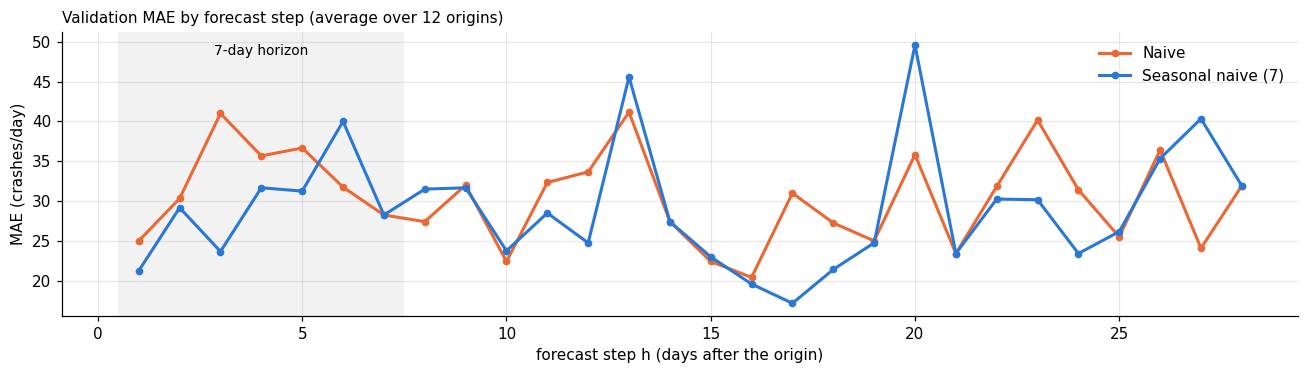

In [22]:
by_h = evaluate_by_horizon(cv_val)
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(by_h.index, by_h["Naive"], color=ORANGE, lw=2, marker="o", ms=4, label="Naive")
ax.plot(by_h.index, by_h["SeasonalNaive"], color=BLUE, lw=2, marker="o", ms=4, label="Seasonal naive (7)")
ax.axvspan(0.5, 7.5, color=GREY, alpha=0.1, lw=0)
ax.text(4, ax.get_ylim()[1] * 0.97, "7-day horizon", ha="center", va="top", fontsize=9)
ax.set_xlabel("forecast step h (days after the origin)")
ax.set_ylabel("MAE (crashes/day)")
ax.set_title("Validation MAE by forecast step (average over 12 origins)", loc="left", fontsize=10)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Per-origin errors (stability).** The table shows MAE over h 1–28 for each validation origin, together with the origin's weekday. The naive forecast copies one day's value for four weeks, so its error depends on which day it copied. The seasonal naive forecast copies a whole week, so it is much less sensitive to the choice of origin.

In [23]:
per_origin = evaluate(cv_val, history=daily, per_window=True)
per_origin = per_origin[per_origin["horizon"] == "h 1-28"]
per_origin = per_origin.pivot_table(index="cutoff", columns="model", values="MAE")
per_origin.insert(0, "origin weekday", per_origin.index.day_name())
per_origin

model,origin weekday,Naive,SeasonalNaive
cutoff,,,
2022-01-18,Tuesday,24.29,30.00
2022-02-16,Wednesday,29.96,28.96
2022-03-17,Thursday,18.96,23.89
2022-04-15,Friday,29.64,29.43
2022-05-14,Saturday,37.43,24.29
2022-06-12,Sunday,35.25,27.82
2022-07-11,Monday,20.21,21.00
2022-08-09,Tuesday,20.79,31.36
2022-09-07,Wednesday,40.18,37.61


#### Test scores (reference only)

The baselines have nothing to tune, so their test scores can be reported now. They are the numbers each member's final model must beat. **Individual models must not look at the test period until tuning on validation is finished.**

In [24]:
test_scores = evaluate(cv_results["test"], history=daily)
test_scores

,,MAE,RMSE,MAPE,MASE,Bias,MAE_sd,n_windows
model,horizon,,,,,,,
Naive,h 1-7,30.57,34.95,11.38,1.02,5.71,14.01,7
SeasonalNaive,h 1-7,29.88,35.29,11.18,1.00,3.96,8.34,7
Naive,h 8-28,37.10,43.26,14.83,1.24,-0.02,19.57,7
SeasonalNaive,h 8-28,32.36,40.97,12.98,1.09,-1.78,7.76,7
Naive,h 1-28,35.46,41.55,13.97,1.19,1.41,17.67,7
SeasonalNaive,h 1-28,31.74,39.73,12.53,1.07,-0.34,7.59,7


In [25]:
summary = pd.concat({"validation": val_scores, "test": test_scores}, names=["period"])
summary = summary.loc[(slice(None), slice(None), ["h 1-7", "h 1-28"]), ["MAE", "RMSE", "MAPE", "MASE", "Bias", "MAE_sd"]]
summary.round(2)

MAE   RMSE   MAPE  MASE  Bias  MAE_sd
period     model         horizon                                         
validation Naive         h 1-7    32.67  38.97  11.60  1.06  2.33   13.08
           SeasonalNaive h 1-7    29.32  36.81  10.84  0.95 -4.11    8.00
test       Naive         h 1-7    30.57  34.95  11.38  1.02  5.71   14.01
           SeasonalNaive h 1-7    29.88  35.29  11.18  1.00  3.96    8.34
validation Naive         h 1-28   30.42  37.27  10.78  0.98  4.18    8.60
           SeasonalNaive h 1-28   29.10  36.76  10.55  0.94 -2.26    4.74
test       Naive         h 1-28   35.46  41.55  13.97  1.19  1.41   17.67
           SeasonalNaive h 1-28   31.74  39.73  12.53  1.07 -0.34    7.59

#### What the baselines tell us

* **Seasonal naive is the baseline to beat.** On validation it has the lowest MAE at both horizons (about 29 crashes per day, MAPE about 10.5%). On the test period it beats naive on every metric over 1–28 days. Its MASE of about 1 says that forecasting four weeks ahead with it is about as accurate as its own one-week-ahead in-sample errors. This makes sense because the post-COVID series has no strong trend.
* **Seasonal naive is also more stable.** Its MAE varies across origins by roughly half as much as naive's (`MAE_sd`). Naive can look competitive on average, but its result depends on which single day it happens to copy. Its per-origin MAE in validation ranges from about 19 to 47, against 21 to 38 for seasonal naive. In the test period, the Friday origin (2023-07-21) gives naive an MAE of about 73.
* **Accuracy decays only slowly with the horizon.** The per-step plot is noisy because each step is averaged over only 12 origins, which is why we compare models on the grouped horizons. Seasonal naive's MAE barely changes from h 1–7 to h 8–28. Most of the error is day-to-day noise (weather, events), not a drifting level. A model will therefore beat this baseline mainly by **modelling the weekly and yearly pattern smoothly** (averaging several past weeks rather than copying one) and by **tracking the slow downward drift**, not by short-term dynamics.
* **The bar is not high in relative terms.** About 10–13% MAPE is a realistic target to improve on with exponential smoothing, ARIMA with weekly seasonality, Prophet-style decomposition, or an ML model with lag features, which is the range of models in our individual notebooks.

### 2.8 How to use this set-up in the individual notebooks

Copy the settings and helper-function cells from Section 2.0 into your notebook unchanged, then:

```python
daily = to_daily(crashes)                     # crashes = raw data, loaded as in Chapter 1

# Option 1: statsforecast models (AutoETS, AutoARIMA, MSTL, ...)
df_cv, cv_kwargs = cv_config(daily, "validation")
cv_df = StatsForecast(models=[...], freq="D").cross_validation(df=df_cv, **cv_kwargs)

# Option 2: any other model. Write a function (train_df, h) -> h forecasts
def my_forecast(train, h):
    ...                                       # fit on train, return an array of length h
cv_df = backtest(my_forecast, daily, "validation", model_name="MyModel")

# Scores, comparable with the baselines above
evaluate(cv_df, history=daily)
evaluate_by_horizon(cv_df)                 # MAE per forecast step, for the horizon plot
```

Rules we propose so that the results are comparable:

1. Tune only on `"validation"`. Run `"test"` once at the end and report it as-is.
2. Use the same `daily` series. A later training start is allowed (use `train_start=` in `backtest`, or filter `df_cv`), but it must be stated.
3. Report `evaluate()` output for your model next to the seasonal naive baseline. Rank by **MAE on h 1–28**, and discuss h 1–7 as well.
4. Exogenous variables (weather, holidays) are allowed only if their values would be known at forecast time. For example, holidays are known in advance, but actual weather is not.

### 2.9 Proposal for the team vote and open points

**Proposal**

| Decision | Proposal |
|---|---|
| Target | Daily number of reported crashes, city-wide. Persons injured per day as an optional secondary target. |
| Horizons | 7 days (rostering) and 28 days (monthly planning), from one 28-day forecast per origin |
| Split | Train to 2021-12-31 · Validation 2022 · Test 2023-01-01 to 2023-08-18 |
| CV scheme | Expanding window, refit at each origin, h = 28, step = 29 days (12 validation origins, 7 test origins) |
| Metrics | MAE (primary), RMSE, MAPE, MASE (one-year scale), Bias, stability (MAE_sd) |
| Baseline to beat | Seasonal naive (7): validation MAE ≈ 29, test MAE ≈ 32 crashes/day over h 1–28 |

**Open points for Mia (outliers / COVID)**, which may move the split dates in the settings cell (Section 2.0):

1. Is the drop from about 550 to about 465 crashes per day between December 2019 and January 2020, *before* the lockdown, a real change or a change in reporting?
2. When does the post-COVID level count as "settled"? This decides whether training should start in mid-2020, in 2021, or use all data.
3. Do the extreme days (e.g. the highest day, 2014-01-21) and holidays need special handling, or are they kept as genuine demand?
4. The last two days of the series (2023-08-17 and 2023-08-18) are unusually low. Is this late reporting at the data snapshot? If so, the test period should end a few days earlier.
5. Why did crashes halve while injuries fell by only about 15%? This is relevant if the team prefers persons injured as the target.

### References (Chapter 2)

Bergmeir, C. (2023) 'Common pitfalls and better practices in forecast evaluation for data scientists', *Foresight: The International Journal of Applied Forecasting*, 70. Available at: https://cbergmeir.com/papers/Bergmeir2023pitfalls.pdf (Accessed: 23 November 2026).

Hyndman, R.J. and Athanasopoulos, G. (2021) *Forecasting: principles and practice*. 3rd edn. Melbourne: OTexts. Available at: https://otexts.com/fpp3/ (Accessed: 23 November 2026).

Hyndman, R.J. and Koehler, A.B. (2006) 'Another look at measures of forecast accuracy', *International Journal of Forecasting*, 22(4), pp. 679–688.

Nixtla (2024) *StatsForecast: lightning fast forecasting with statistical and econometric models*. Available at: https://nixtlaverse.nixtla.io/statsforecast/ (Accessed: 23 November 2026).

NYC Open Data (2023) *Motor Vehicle Collisions – Crashes*. New York City Police Department. Available at: https://data.cityofnewyork.us/Public-Safety/Motor-Vehicle-Collisions-Crashes/h9gi-nx95 (Accessed: 23 November 2026).

Tashman, L.J. (2000) 'Out-of-sample tests of forecasting accuracy: an analysis and review', *International Journal of Forecasting*, 16(4), pp. 437–450.
